In [2]:
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
data = joblib.load("../src/data_splits.pkl")

x_train = data["x_train"]
x_val = data["x_val"]
x_test = data["x_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

classes = data['classes']

In [4]:
# resize + normalize
IMG_SIZE = (150 , 150)
def proces_img(img_path):
    img = tf.keras.utils.load_img(img_path , target_size=IMG_SIZE)
    img = tf.keras.utils.img_to_array(img)
    img = img /255.0
    return img


In [5]:
# encoding the labels
label_indexes = list(classes.keys())
index_labels = {name : index   for index , name in enumerate(label_indexes)}

y_train = [index_labels[item] for item in y_train ] 
y_test = [index_labels[item] for item in y_test ] 
y_val = [index_labels[item] for item in y_val ] 

In [6]:
# create batches
# transform and normalize data
BATCH_SIZE = 32

def create_dataset(img_paths, labels, training=False):
    data = tf.data.Dataset.from_tensor_slices((img_paths, labels))

    if training:
        data = data.shuffle(buffer_size=len(img_paths))

    def load_and_process(label , path) :
        img = tf.numpy_function(proces_img , [path] , tf.float32)
        img.set_shape((150 , 150 , 3))
        return  img , label

    data = data.map(
        lambda path, label: load_and_process(label , path),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    data = data.batch(BATCH_SIZE)
    data = data.prefetch(tf.data.AUTOTUNE)
    return data

In [7]:
# create 3 datasets
dts_train = create_dataset(x_train , y_train , training=True)
dts_test = create_dataset(x_test , y_test , training=True)
dts_val = create_dataset(x_val , y_val , training=True)

In [8]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomRotation(0.1)
])

In [9]:
dts_train =  dts_train.map(
    lambda images , label : (data_augmentation(images, training=True), label) ,
    num_parallel_calls=tf.data.AUTOTUNE   
)

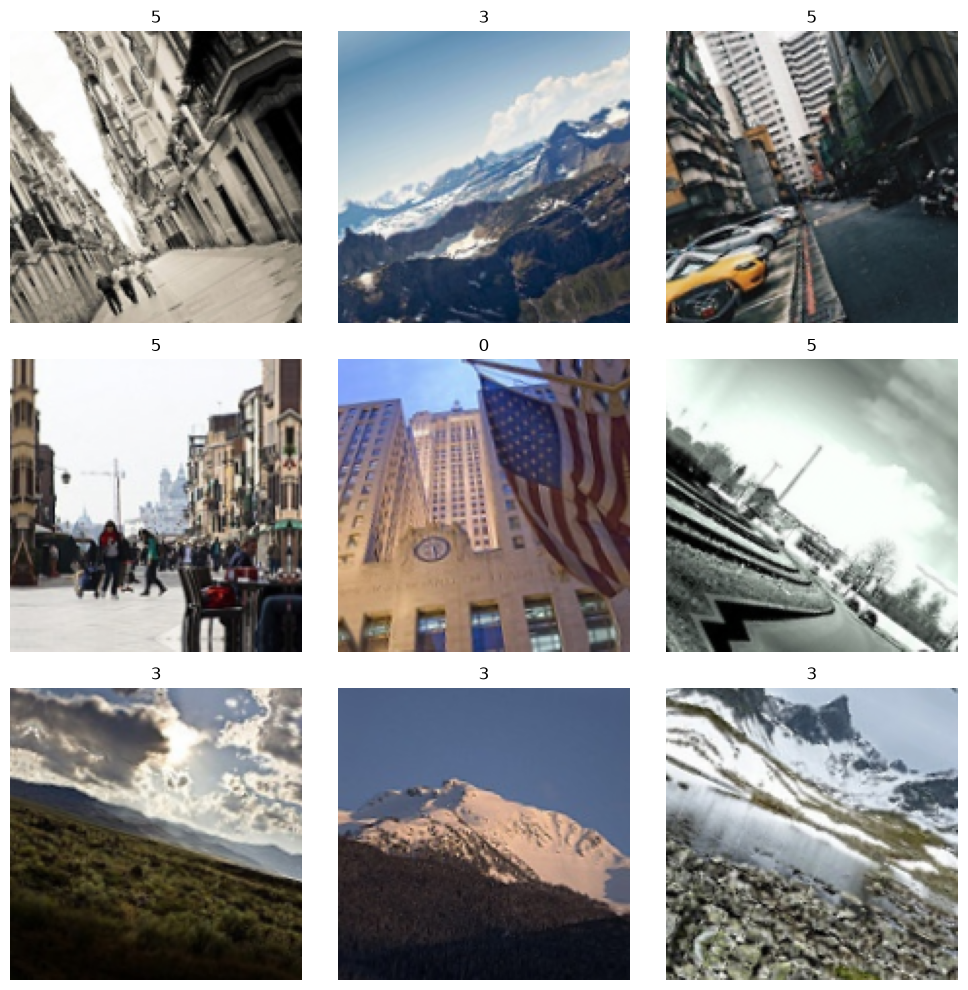

In [10]:
for images, labels in dts_train.take(1):
    plt.figure(figsize=(10, 10))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(labels[i].numpy())
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [11]:
# save datasets
dts_train.save("../src/dts_train")
dts_test.save("../src/dts_test")
dts_val.save("../src/dts_val")

In [12]:
# # initialise model
# model = tf.keras.models.Sequential()
# # inputs layer
# model.add(tf.keras.layers.Flatten(x_train))
# model.add(tf.keras.layers.Dense(128 , activation=tf.nn.relu))
# model.add(tf.keras.layers.Dense(128 , activation=tf.nn.relu))
# model.add(tf.keras.layers.Dense(6 , activation=tf.nn.softmax))

# model.compile(optimer="adam",loss="categorical_crossentropy" , matrics=['acuracy']) 
# model.fit(x_train , y_train , epochs=10)


In [13]:
# x_train = tf.keras.utils.normalize(x_train , axis=1)

In [14]:
# normalization
# x_train = tf.keras.utils.normalize(x_train , axis=1)
# x_val = tf.keras.utils.normalize(x_val , axis=1)
# x_test = tf.keras.utils.normalize(x_test , axis=1)